# Game of Life

Every cell of a 50 × 50 grid (wrapping round at the edges) is an agent, alive or dead. Each step, every cell counts its 8 live neighbours. A live cell survives with 2 or 3 live neighbours, and a dead cell comes alive with exactly 3. All cells update at once. Slide 8.

*Made for this site, following the rules on the slides (`1 Lecture/Agent Based Modelling with Mesa - Slides.html`). It uses Mesa 3 (`mesa.discrete_space`), tested with Mesa 3.5.1 in the browser. The interactive Solara versions on py.cafe, linked from the slides, need the internet and run outside this site.*

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install mesa networkx

In [2]:
import mesa
from mesa.discrete_space import OrthogonalMooreGrid, FixedAgent
import numpy as np
import matplotlib.pyplot as plt

**The model.** Each step has two phases: every cell first decides its next state, then all cells switch together.

In [3]:
class LifeCell(FixedAgent):
    def __init__(self, model, cell, alive):
        super().__init__(model)
        self.cell = cell
        self.alive = alive
        self.next_alive = alive

    def decide(self):
        n = sum(a.alive for a in self.cell.neighborhood.agents)
        self.next_alive = (n == 3) or (self.alive and n == 2)

    def update(self):
        self.alive = self.next_alive


class GameOfLife(mesa.Model):
    def __init__(self, width=50, height=50, p_alive=0.25, seed=1):
        super().__init__(rng=seed)
        self.grid = OrthogonalMooreGrid((width, height), torus=True, random=self.random)
        for cell in self.grid.all_cells:
            LifeCell(self, cell, self.random.random() < p_alive)

    def step(self):
        self.agents.do("decide")
        self.agents.do("update")

    def picture(self):
        w, h = self.grid.dimensions
        img = np.zeros((h, w))
        for a in self.agents:
            x, y = a.cell.coordinate
            img[y, x] = a.alive
        return img

**Run it** and show the grid at a few times, plus the number of live cells. Predict first: does the population die out, explode or settle?

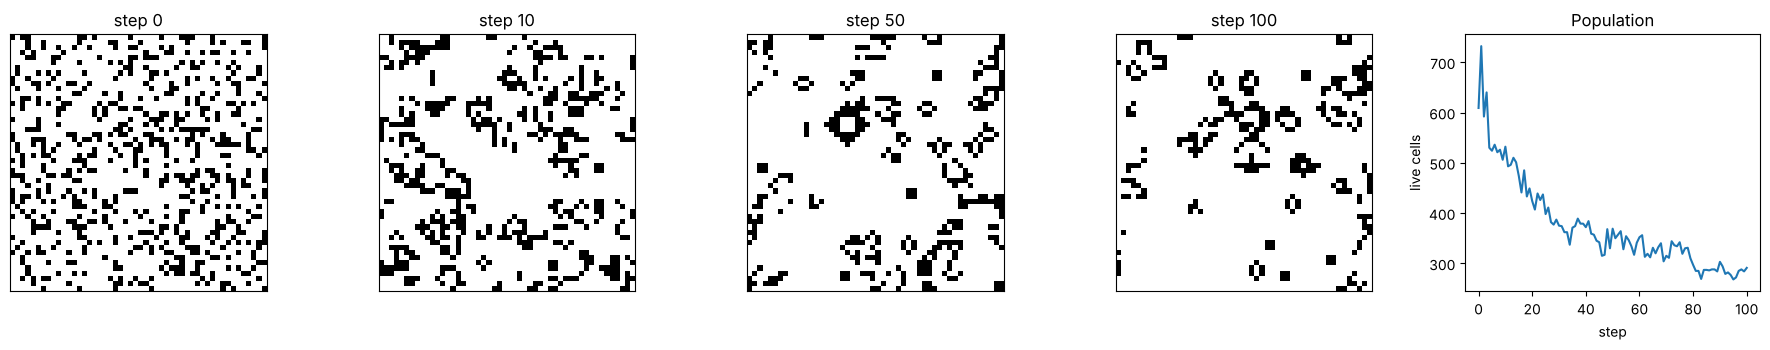

Live cells: 609 at the start, 291 after 100 steps


In [4]:
model = GameOfLife()
snapshots, live = {}, []
for t in range(101):
    if t in (0, 10, 50, 100):
        snapshots[t] = model.picture()
    live.append(sum(a.alive for a in model.agents))
    model.step()

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, (t, img) in zip(axes, snapshots.items()):
    ax.imshow(img, cmap="Greys", interpolation="nearest"); ax.set(title=f"step {t}", xticks=[], yticks=[])
axes[-1].plot(live); axes[-1].set(xlabel="step", ylabel="live cells", title="Population")
plt.tight_layout(); plt.show()
print(f"Live cells: {live[0]} at the start, {live[-1]} after 100 steps")